In [2]:
%load_ext autoreload
%autoreload 2

This notebook determines the range of fire areas in which the 3 fire area datasets are in agreement by minimizing the Kuiper statistic of their CDFs over the region where the datasets overlap spatially and temporally.

In [1]:
import numpy as np

from wildfire_stats import config as cfg
from wildfire_stats.data import io as dio
from wildfire_stats.plotting import dataset_comp as pdc
from wildfire_stats.reporting import summaries as rsum

P = cfg.load_paths()
A = cfg.load_assumptions()

### MTBS vs. GFD

In [3]:
mtbs_proj = dio.load_mtbs(P.mtbs / "S_USA.MTBS_BURN_AREA_BOUNDARY.shp",
                          area_col="area_km2")
idaho_gdf = dio.load_idaho(P.idaho / "HFD_HistoricFiresDatabase8_0.gdb")

# MTBS starts in 1984; GFA / MODIS cover modis_years
mtbs_proj = dio.filter_years(mtbs_proj, "YEAR", (1984, 2016))
idaho_gdf = dio.filter_years(idaho_gdf, "FIRE_YEAR", (1984, 2016))
idaho_gdf2 = dio.filter_years(idaho_gdf, "FIRE_YEAR", A["modis_years"])

mtbs_overlap = dio.overlap_with(mtbs_proj, idaho_gdf, dedup_col="FIRE_ID")

rsum.print_summary("MTBS", mtbs_overlap, "YEAR")
rsum.print_summary("Idaho", idaho_gdf, "FIRE_YEAR")

/project/bbcael/ambauer/envs/wildfire_stats/lib/python3.10/site-packages/pyogrio/raw.py:198: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(
/project/bbcael/ambauer/envs/wildfire_stats/lib/python3.10/site-packages/pyogrio/raw.py:198: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts. The processing may be really slow.  You can skip the processing by setting METHOD=SKIP, or only make it analyze counter-clock wise parts by setting METHOD=ONLY_CCW if you can assume that the outline of holes is counter-clock wise defined
  return ogr_read(



MTBS dataset:
  Number of fires: 8736
  Year range: 1984 - 2016
  Mean fire size: 38.23 km²
  Median fire size: 11.94 km²
  Min fire size: 4.05 km²
  Max fire size: 2296.22 km²
  Total burned area: 333992.45 km²

Idaho dataset:
  Number of fires: 33354
  Year range: 1984 - 2016
  Mean fire size: 11.03 km²
  Median fire size: 0.67 km²
  Min fire size: 0.00 km²
  Max fire size: 2462.94 km²
  Total burned area: 367836.11 km²


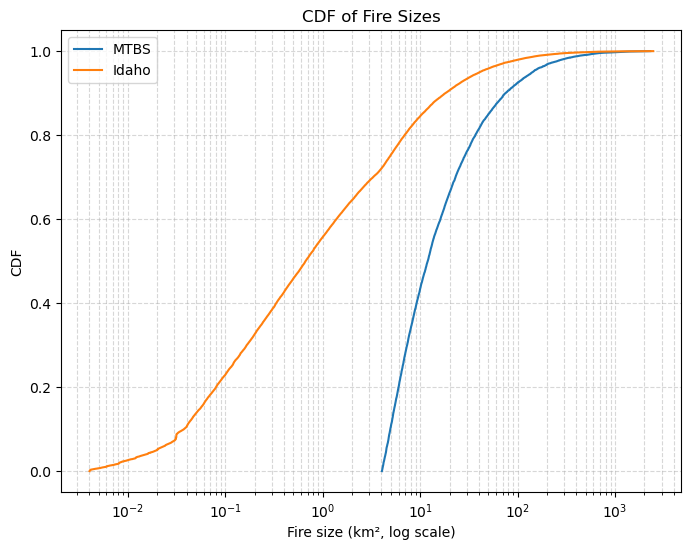

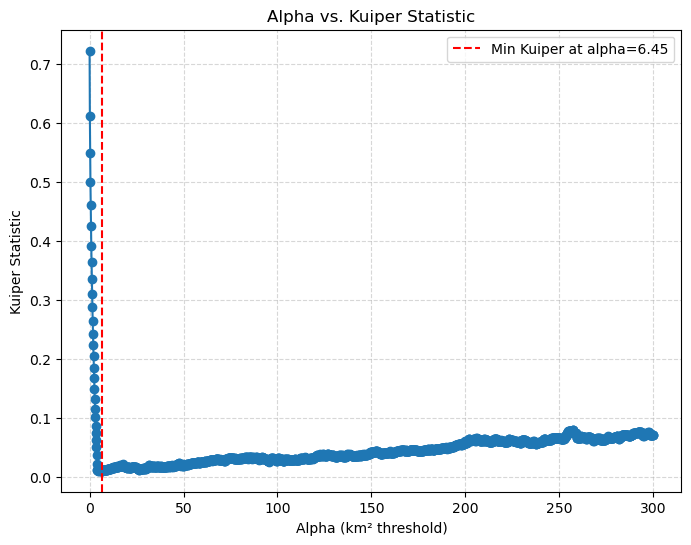

Minimum Kuiper statistic 0.0101 occurs at alpha = 6.4532 km²


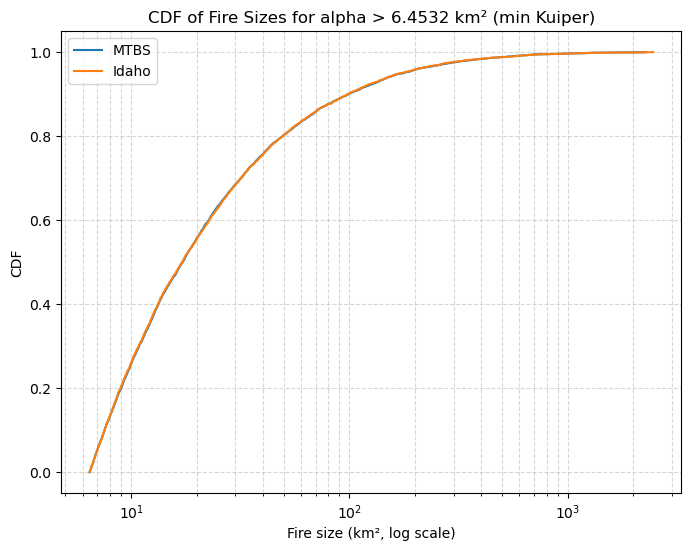

(np.float64(6.453226613306654), np.float64(0.010077897767335725))

: 

In [ ]:
alphas = np.linspace(0, 300, 2000)

pdc.plot_cdf_vs_area(mtbs_overlap, idaho_gdf, labels=("MTBS", "Idaho"))
pdc.plot_alpha_vs_kuiper_with_min_cdf(mtbs_overlap, idaho_gdf, 
                                      alphas, labels=("MTBS", "Idaho"))

### GFA vs. GFD

In [ ]:
gfa_combined_gdf = dio.load_gfa(P.gfa, verbose=True)

gfa_overlap = dio.overlap_with(gfa_combined_gdf, idaho_gdf2, dedup_col="geometry")

Processing /project/bbcael/private/ambauer/wildfire-stats/gfa/data/Global_fire_atlas_V1_perimeter_2003.shp ...
Processing /project/bbcael/private/ambauer/wildfire-stats/gfa/data/Global_fire_atlas_V1_perimeter_2004.shp ...
Processing /project/bbcael/private/ambauer/wildfire-stats/gfa/data/Global_fire_atlas_V1_perimeter_2005.shp ...
Processing /project/bbcael/private/ambauer/wildfire-stats/gfa/data/Global_fire_atlas_V1_perimeter_2006.shp ...


In [16]:
gfa_combined_gdf

,fire_ID,geometry,YEAR,landcover_s


In [6]:
rsum.print_summary("GFA (overlap)", gfa_overlap, "YEAR")
rsum.print_summary("Idaho", idaho_gdf2, "FIRE_YEAR")


GFA (overlap) dataset:
  Number of fires: 0
  Year range: nan - nan


KeyError: 'area_km2'

In [ ]:
alphas2 = np.linspace(0, 200, 2000)

pdc.plot_cdf_vs_area(gfa_overlap, idaho_gdf2, labels=("GFA", "Idaho"))
pdc.plot_alpha_vs_kuiper_with_min_cdf(gfa_overlap, idaho_gdf2, alphas2, 
                                      labels=("GFA", "Idaho"))

### GFA vs. MTBS

In [ ]:
pdc.plot_cdf_vs_area(gfa_overlap, mtbs_overlap, labels=("GFA", "MTBS"))
pdc.plot_alpha_vs_kuiper_with_min_cdf(gfa_overlap, mtbs_overlap, alphas2, 
                                      labels=("GFA", "MTBS"))

Based on the minimum fire size cutoffs that minimize the Kuiper statistic, all future notebooks will remove fires less than 4 km^2.